<a href="https://colab.research.google.com/github/prksh830/Healthcare/blob/main/CRPL_AFNet_HeartDisease.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
pip install catboost

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.1/97.1 MB 8.8 MB/s eta 0:00:00


In [ ]:
# ============================================================
# Dataset Summary
# ============================================================

def dataset_summary(df, dataset_name):

    print("=" * 70)
    print(f"DATASET : {dataset_name}")
    print("=" * 70)

    print(f"Shape : {df.shape}")

    print("\n")

    print(df.info())

    print("\n")

    print(df.describe(include='all'))

    print("\nMissing Values")

    print(df.isnull().sum())

    print("\nDuplicate Rows")

    print(df.duplicated().sum())

    print("=" * 70)

In [ ]:
dataset_summary(cvd_df,"CVD Dataset")

dataset_summary(diab_df,"Diabetes Dataset")

DATASET : CVD Dataset
Shape : (308854, 19)


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 308854 entries, 0 to 308853
Data columns (total 19 columns):
 #   Column                        Non-Null Count   Dtype  
---  ------                        --------------   -----  
 0   General_Health                308854 non-null  object 
 1   Checkup                       308854 non-null  object 
 2   Exercise                      308854 non-null  object 
 3   Skin_Cancer                   308854 non-null  object 
 4   Other_Cancer                  308854 non-null  object 
 5   Depression                    308854 non-null  object 
 6   Diabetes                      308854 non-null  object 
 7   Arthritis                     308854 non-null  object 
 8   Sex                           308854 non-null  object 
 9   Age_Category                  308854 non-null  object 
 10  Height_(cm)                   308854 non-null  int64  
 11  Weight_(kg)                   308854 non-null  float64
 12 

In [ ]:
# ============================================================
# Duplicate Removal
# ============================================================

def remove_duplicates(df):

    before = len(df)

    df = df.drop_duplicates()

    after = len(df)

    print(f"Removed : {before-after}")

    print(f"Remaining : {after}")

    return df


cvd_df = remove_duplicates(cvd_df)

diab_df = remove_duplicates(diab_df)

Removed : 80
Remaining : 308774
Removed : 3854
Remaining : 96146


In [ ]:
# ============================================================
# Figure Saving
# ============================================================

def save_figure(name):

    png_path=f"Results/Figures/PNG/{name}.png"

    jpg_path=f"Results/Figures/JPG/{name}.jpg"

    tiff_path=f"Results/Figures/TIFF/{name}.tiff"

    plt.savefig(
        png_path,
        dpi=600,
        bbox_inches="tight"
    )

    plt.savefig(
        jpg_path,
        dpi=600,
        bbox_inches="tight"
    )

    plt.savefig(
        tiff_path,
        dpi=600,
        bbox_inches="tight"
    )

In [ ]:
# ============================================================
# Target Distribution
# ============================================================

def plot_target_distribution(df,target,title):

    plt.figure(figsize=(7,6))

    ax=sns.countplot(
        data=df,
        x=target,
        palette="viridis"
    )

    plt.title(title,
              fontsize=18,
              weight='bold')

    plt.xlabel("Class",
               fontsize=15,
               weight='bold')

    plt.ylabel("Count",
               fontsize=15,
               weight='bold')

    for container in ax.containers:
        ax.bar_label(container,
                     fontsize=14,
                     weight='bold')

    plt.tight_layout()

    save_figure(title)

    plt.show()

In [ ]:
def correlation_plot(df,title):

    plt.figure(figsize=(15,12))

    corr=df.corr(numeric_only=True)

    sns.heatmap(
        corr,
        annot=True,
        fmt=".2f",
        cmap="coolwarm",
        linewidths=.5,
        annot_kws={
            "size":10,
            "weight":"bold"
        }
    )

    plt.xticks(
        fontsize=12,
        weight='bold',
        rotation=45
    )

    plt.yticks(
        fontsize=12,
        weight='bold'
    )

    plt.title(
        title,
        fontsize=20,
        weight='bold'
    )

    plt.tight_layout()

    save_figure(title)

    plt.show()

In [ ]:
# ============================================================
# Create Figure Directories
# ============================================================

directories = [
    "Results",
    "Results/Figures",
    "Results/Figures/PNG",
    "Results/Figures/JPG",
    "Results/Figures/TIFF",
    "Results/Models",
    "Results/Predictions",
    "Results/SHAP",
    "Results/Tables"
]

for directory in directories:
    os.makedirs(directory, exist_ok=True)

print("Project directories created successfully.")

Project directories created successfully.


In [ ]:
# ============================================================
# Dataset Information
# ============================================================

print("="*80)
print("CVD DATASET")
print("="*80)

display(cvd_df.info())

print("\n")

print("="*80)
print("DIABETES DATASET")
print("="*80)

display(diab_df.info())

CVD DATASET
<class 'pandas.core.frame.DataFrame'>
Index: 308774 entries, 0 to 308853
Data columns (total 19 columns):
 #   Column                        Non-Null Count   Dtype  
---  ------                        --------------   -----  
 0   General_Health                308774 non-null  object 
 1   Checkup                       308774 non-null  object 
 2   Exercise                      308774 non-null  object 
 3   Skin_Cancer                   308774 non-null  object 
 4   Other_Cancer                  308774 non-null  object 
 5   Depression                    308774 non-null  object 
 6   Diabetes                      308774 non-null  object 
 7   Arthritis                     308774 non-null  object 
 8   Sex                           308774 non-null  object 
 9   Age_Category                  308774 non-null  object 
 10  Height_(cm)                   308774 non-null  int64  
 11  Weight_(kg)                   308774 non-null  float64
 12  BMI                           308774 

None



DIABETES DATASET
<class 'pandas.core.frame.DataFrame'>
Index: 96146 entries, 0 to 99999
Data columns (total 9 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   gender               96146 non-null  object 
 1   age                  96146 non-null  float64
 2   hypertension         96146 non-null  int64  
 3   smoking_history      96146 non-null  object 
 4   bmi                  96146 non-null  float64
 5   HbA1c_level          96146 non-null  float64
 6   blood_glucose_level  96146 non-null  int64  
 7   diabetes             96146 non-null  int64  
 8   heart_disease        96146 non-null  int64  
dtypes: float64(3), int64(4), object(2)
memory usage: 7.3+ MB


None

In [ ]:
# ============================================================
# Missing Values
# ============================================================

print("CVD Dataset")
display(cvd_df.isnull().sum())

print("\n")

print("Diabetes Dataset")
display(diab_df.isnull().sum())

CVD Dataset


,0
General_Health,0
Checkup,0
Exercise,0
Skin_Cancer,0
Other_Cancer,0
Depression,0
Diabetes,0
Arthritis,0
Sex,0
Age_Category,0




Diabetes Dataset


,0
gender,0
age,0
hypertension,0
smoking_history,0
bmi,0
HbA1c_level,0
blood_glucose_level,0
diabetes,0
heart_disease,0


In [ ]:
# ============================================================
# Duplicate Records
# ============================================================

print("CVD Duplicate Rows :", cvd_df.duplicated().sum())
print("Diabetes Duplicate Rows :", diab_df.duplicated().sum())

CVD Duplicate Rows : 0
Diabetes Duplicate Rows : 0


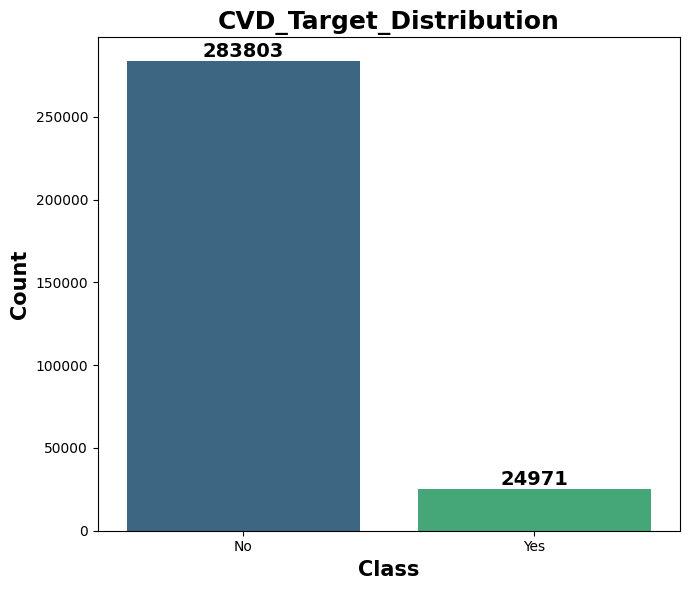

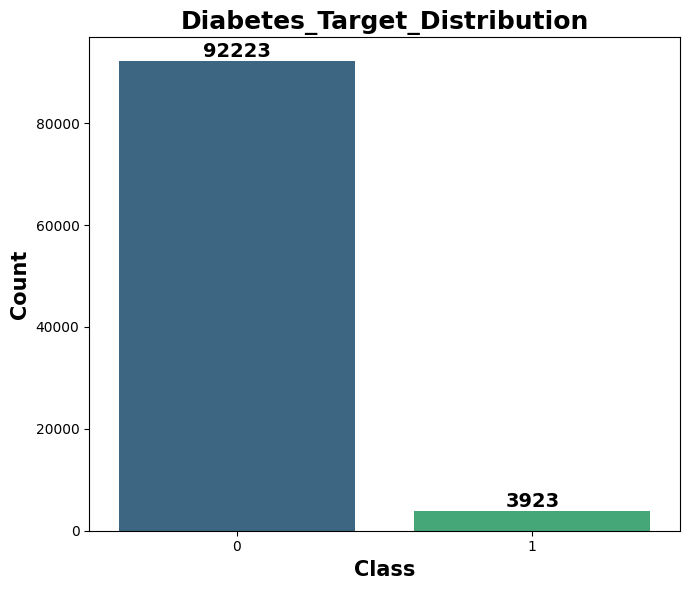

In [ ]:
plot_target_distribution(
    cvd_df,
    "Heart_Disease",
    "CVD_Target_Distribution"
)

plot_target_distribution(
    diab_df,
    "heart_disease",
    "Diabetes_Target_Distribution"
)

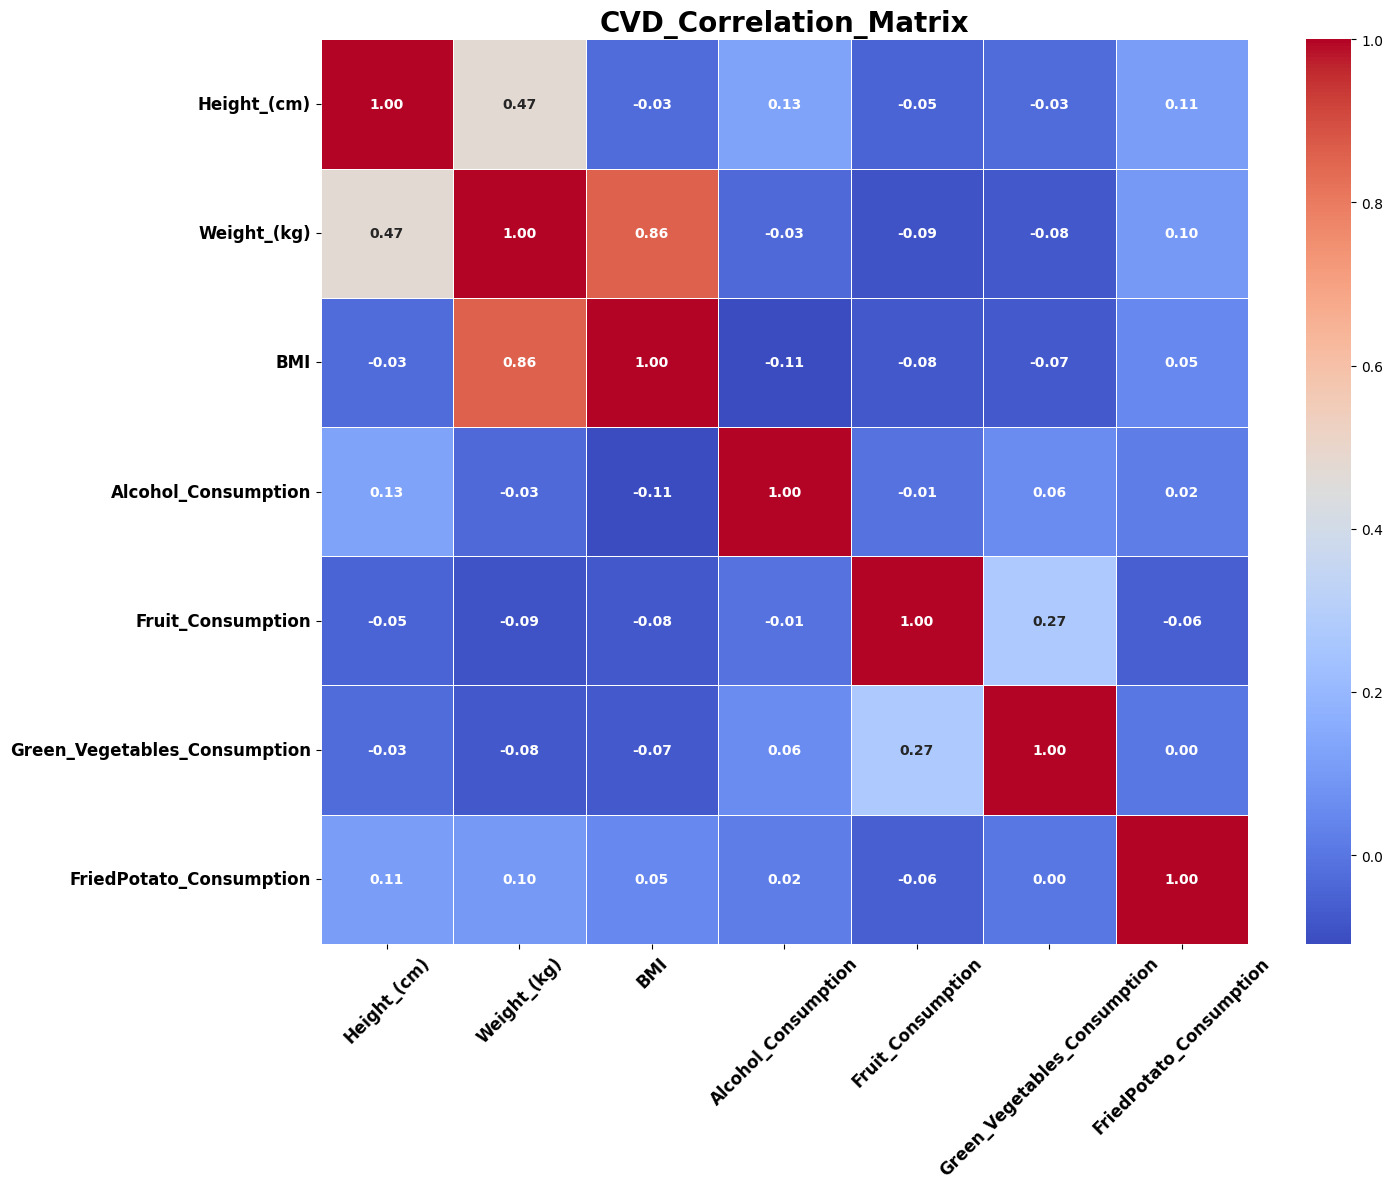

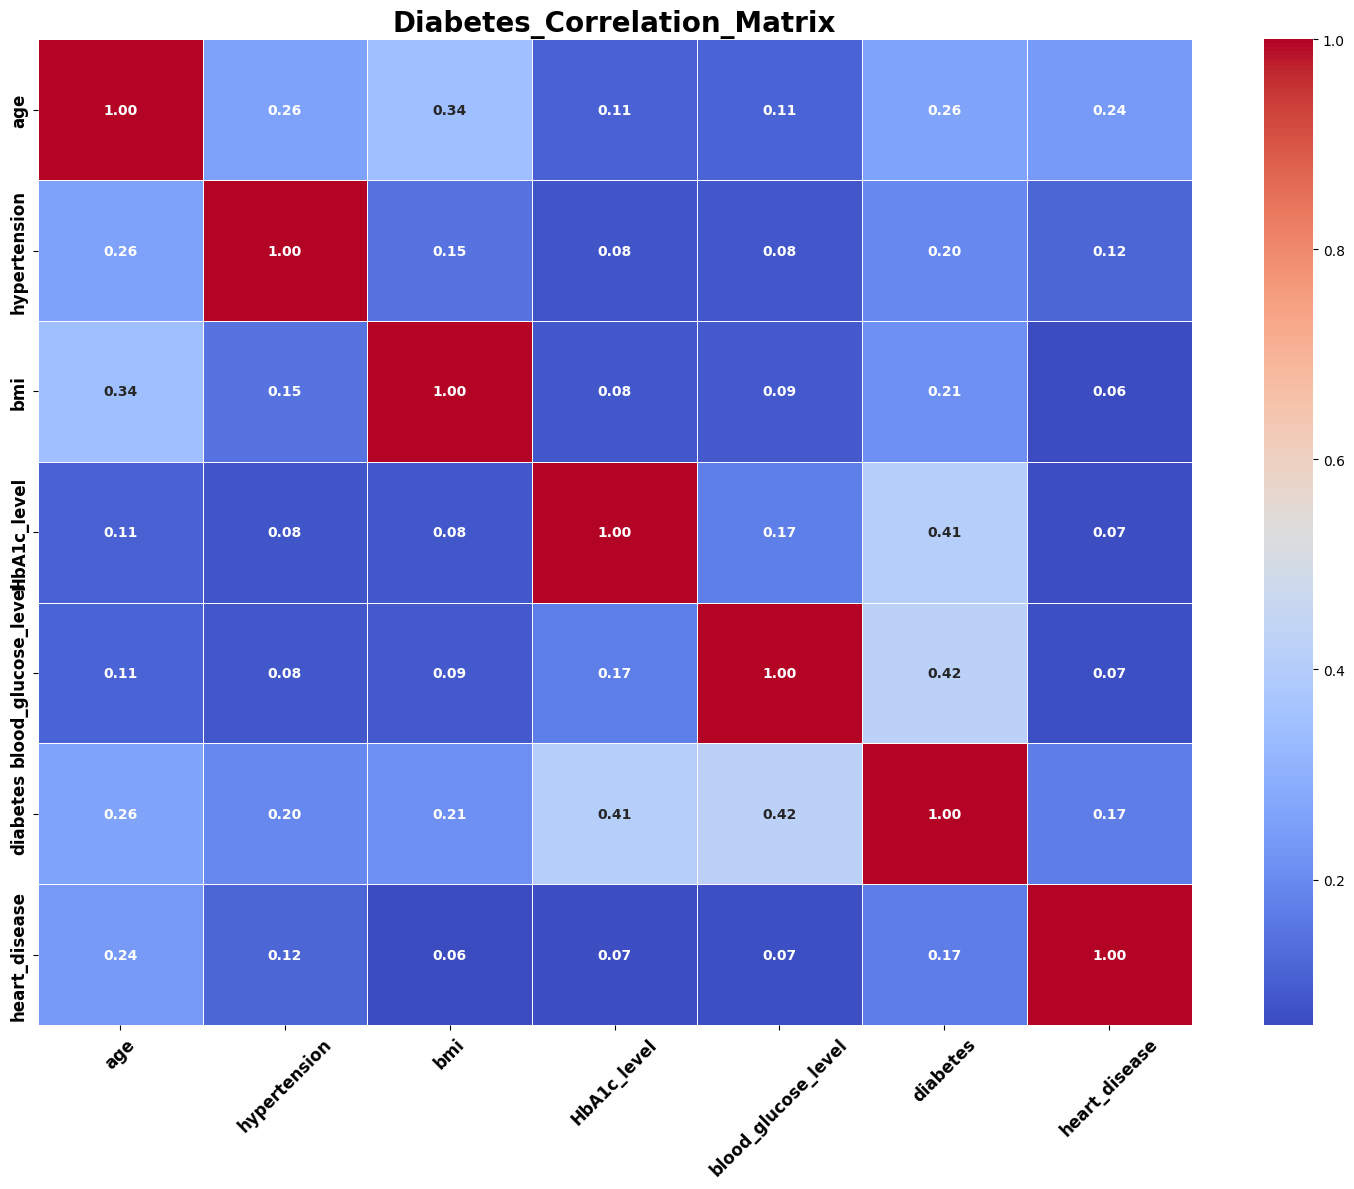

In [ ]:
correlation_plot(
    cvd_df,
    "CVD_Correlation_Matrix"
)

correlation_plot(
    diab_df,
    "Diabetes_Correlation_Matrix"
)

In [ ]:
def plot_numeric_distribution(df, dataset_name):

    numeric_cols = df.select_dtypes(include=np.number).columns

    for col in numeric_cols:

        plt.figure(figsize=(7,5))

        sns.histplot(
            df[col],
            kde=True
        )

        plt.title(
            f"{dataset_name}_{col}",
            fontsize=18,
            fontweight='bold'
        )

        plt.xlabel(col, fontsize=14, fontweight='bold')
        plt.ylabel("Frequency", fontsize=14, fontweight='bold')

        plt.tight_layout()

        save_figure(f"{dataset_name}_{col}_Distribution")

        plt.show()

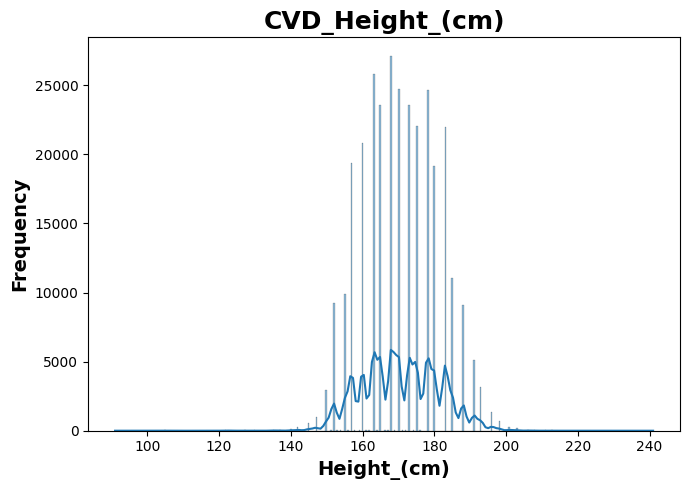

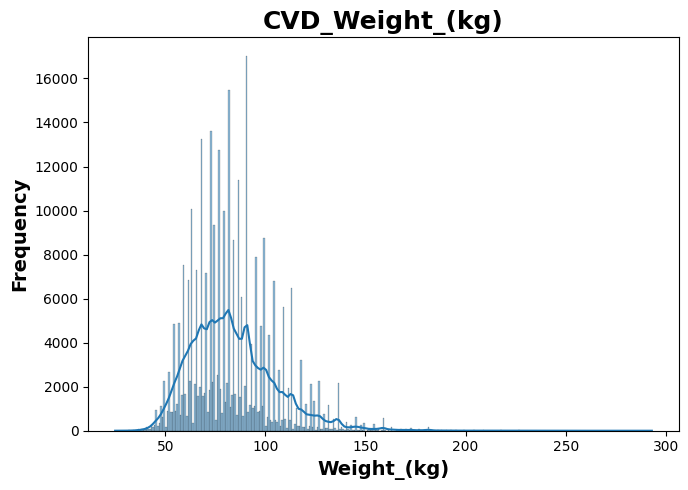

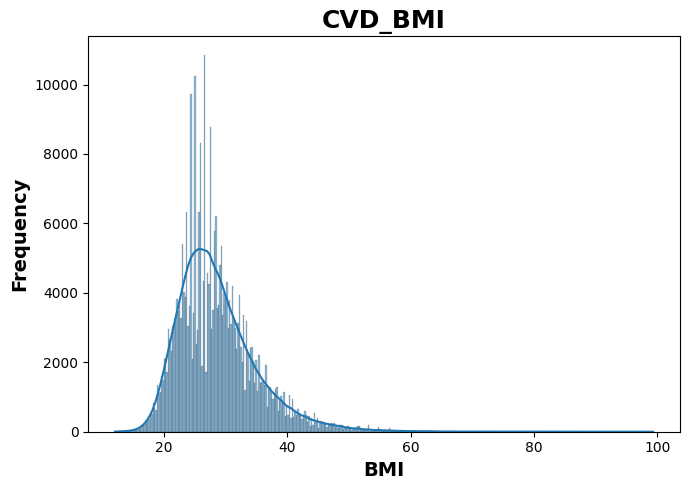

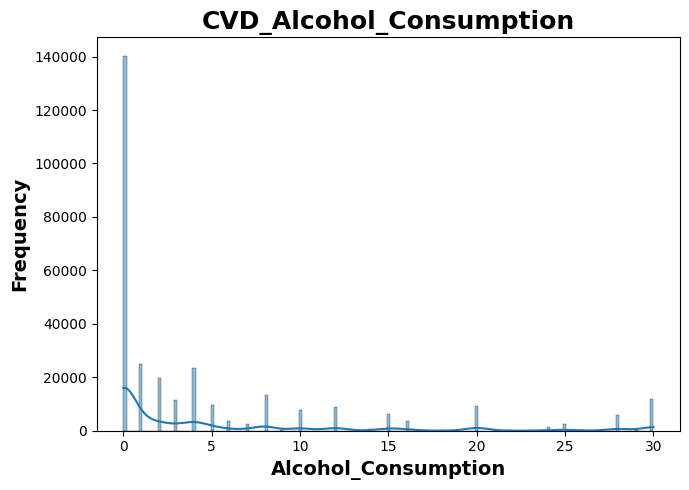

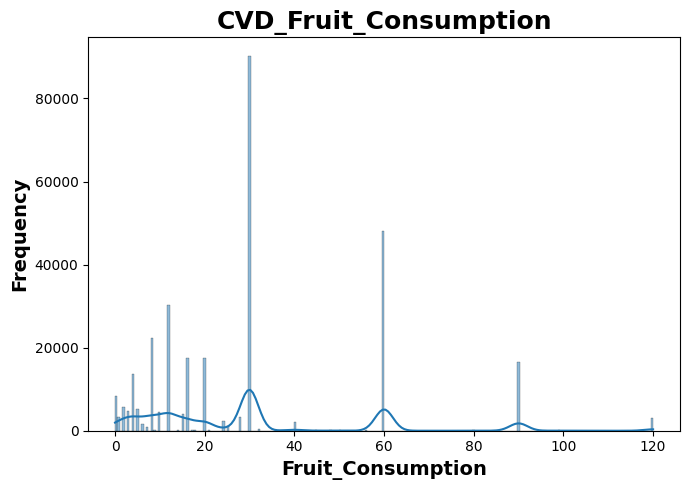

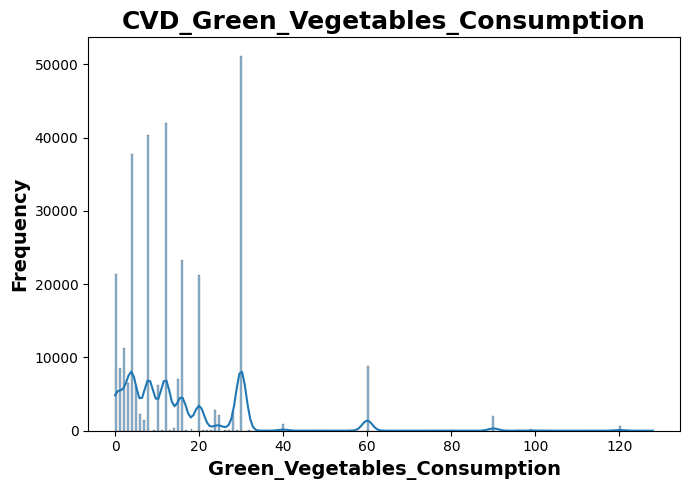

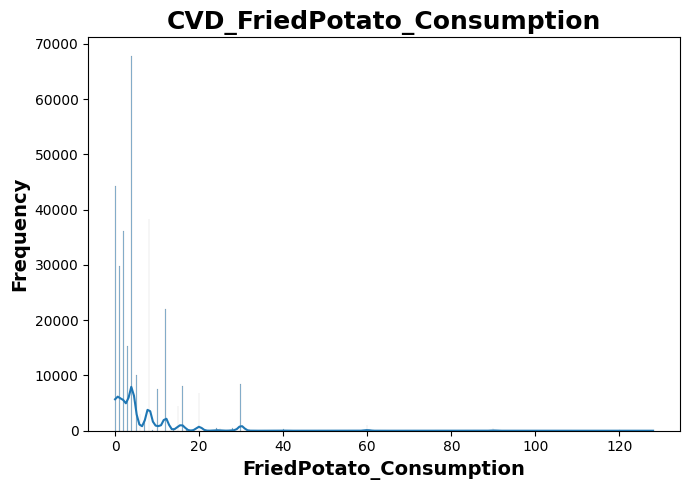

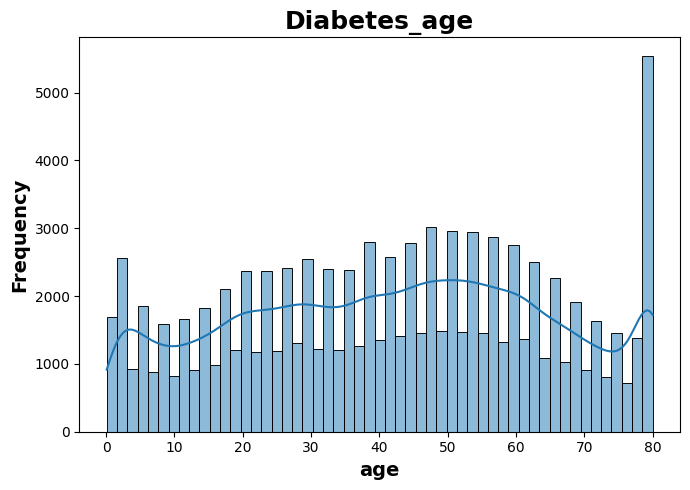

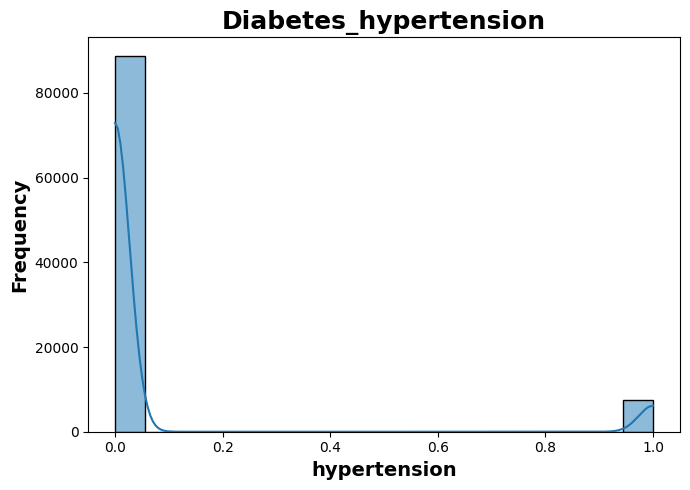

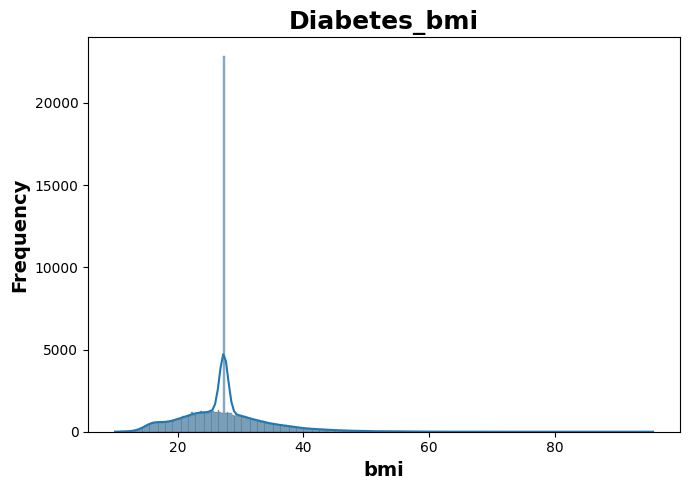

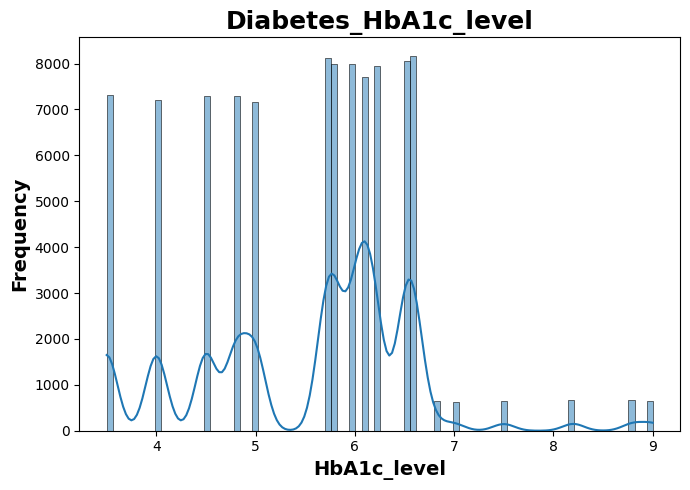

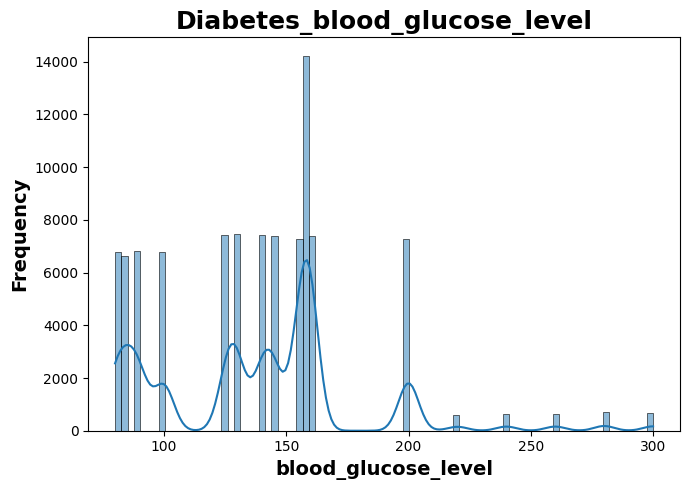

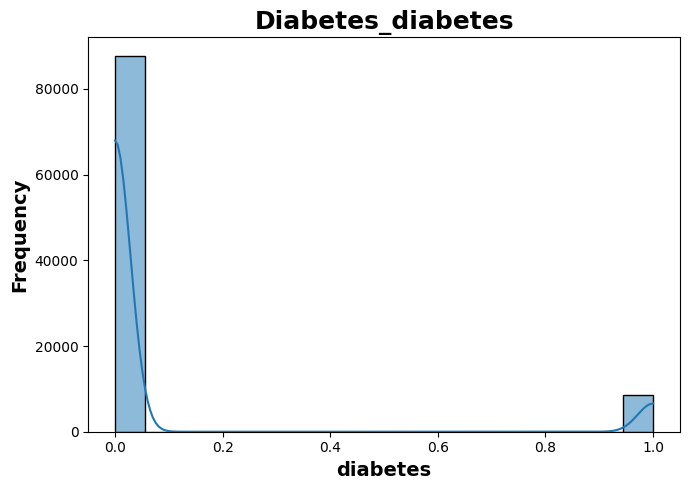

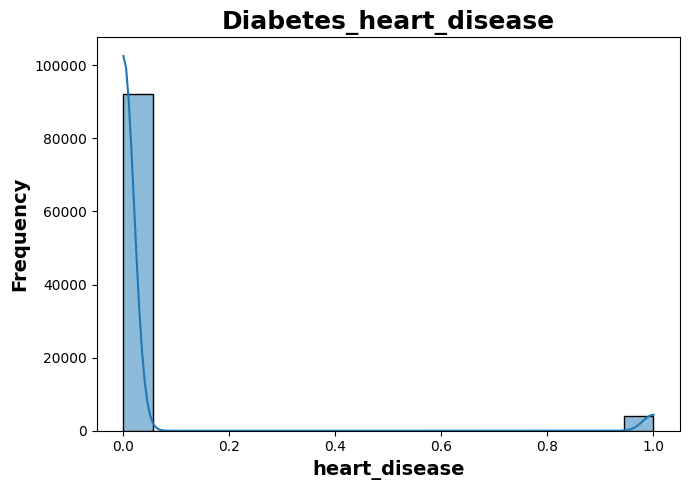

In [ ]:
plot_numeric_distribution(cvd_df, "CVD")

plot_numeric_distribution(diab_df, "Diabetes")

In [ ]:
def plot_boxplots(df, dataset_name):

    numeric_cols = df.select_dtypes(include=np.number).columns

    for col in numeric_cols:

        plt.figure(figsize=(7,5))

        sns.boxplot(x=df[col])

        plt.title(
            f"{dataset_name}_{col}_Boxplot",
            fontsize=18,
            fontweight='bold'
        )

        plt.tight_layout()

        save_figure(f"{dataset_name}_{col}_Boxplot")

        plt.show()

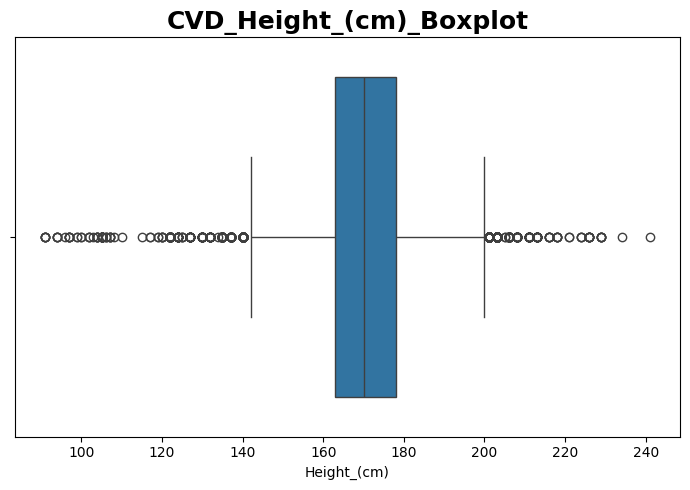

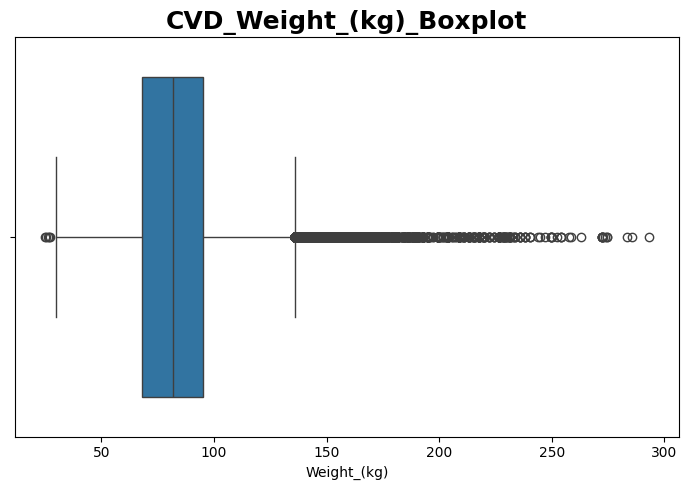

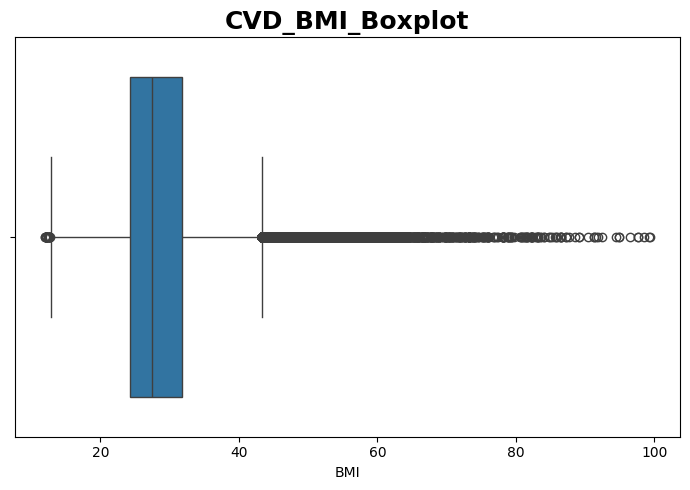

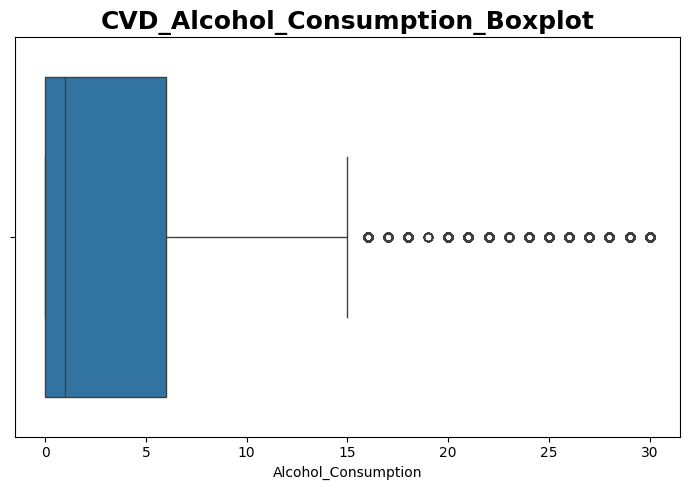

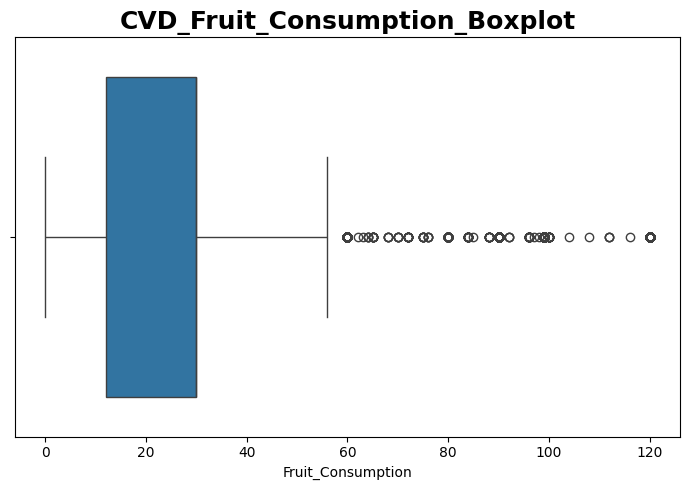

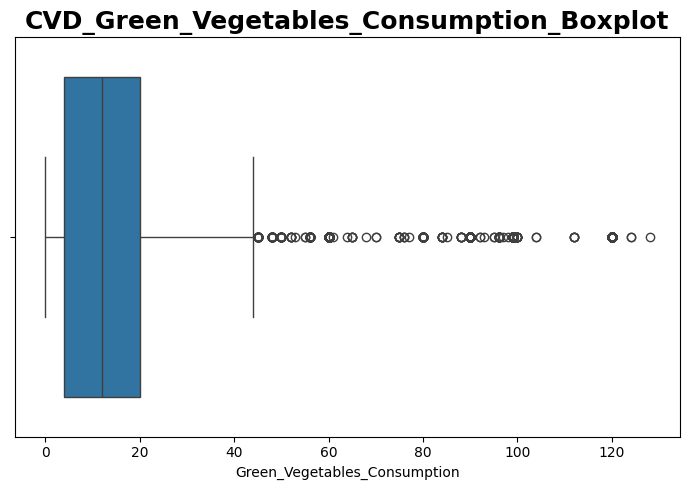

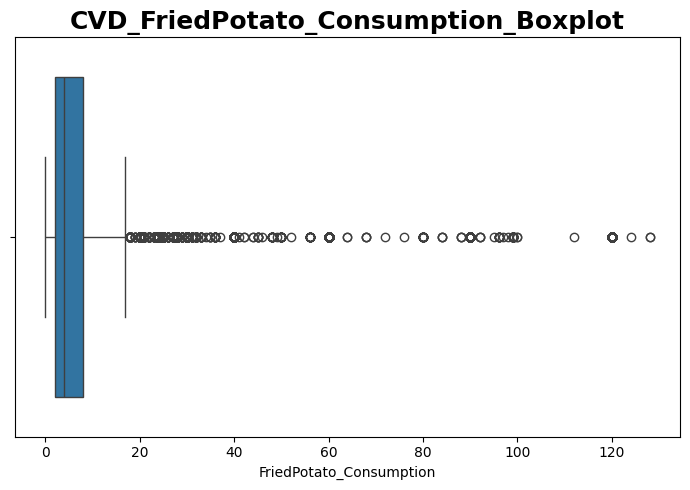

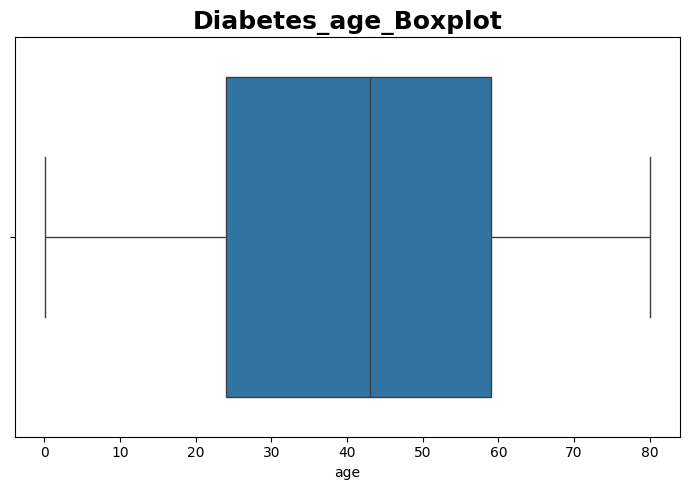

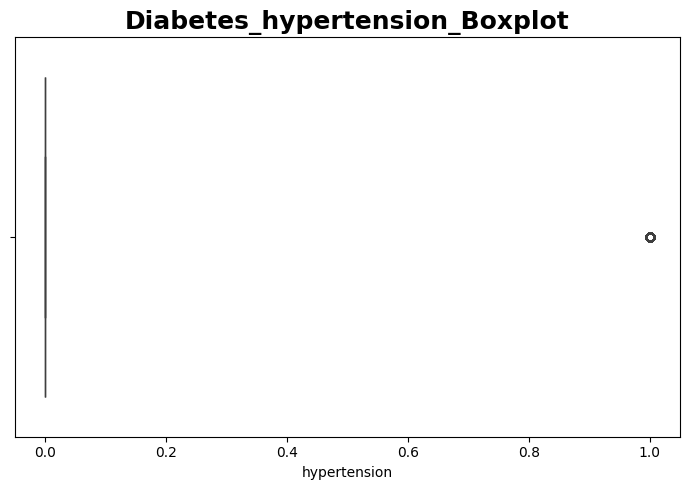

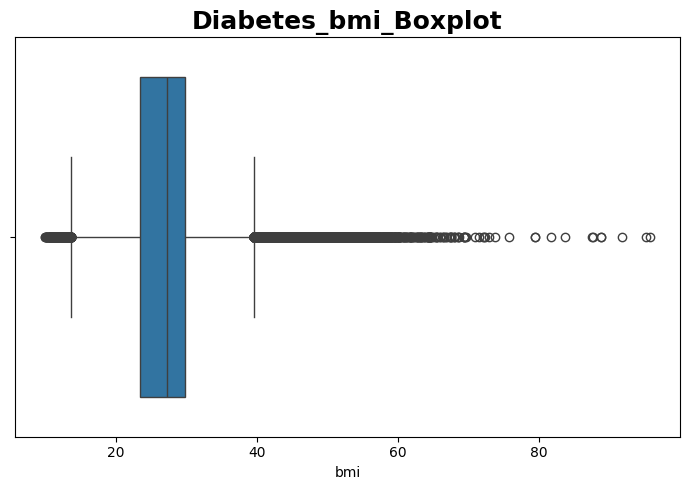

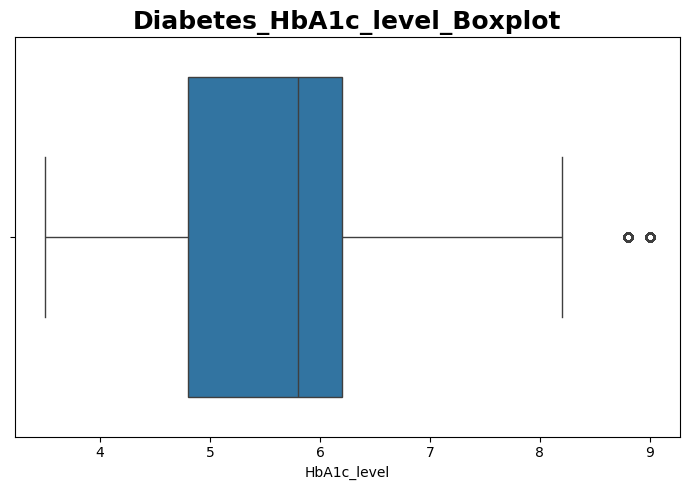

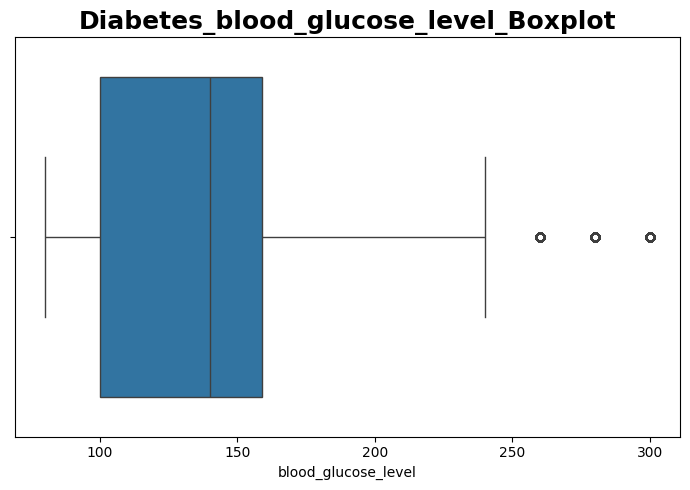

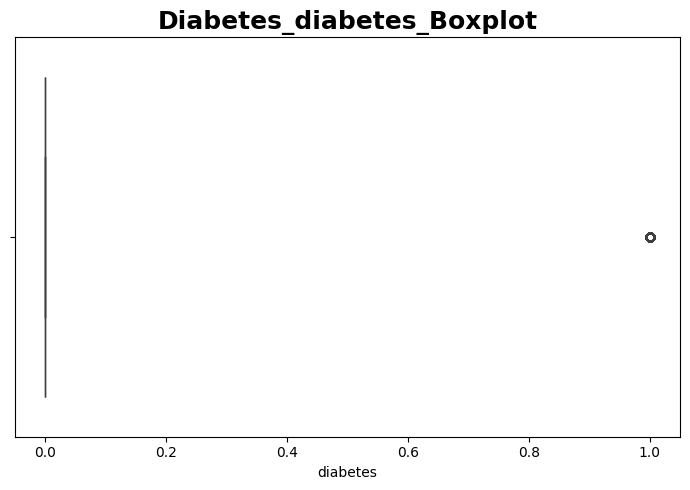

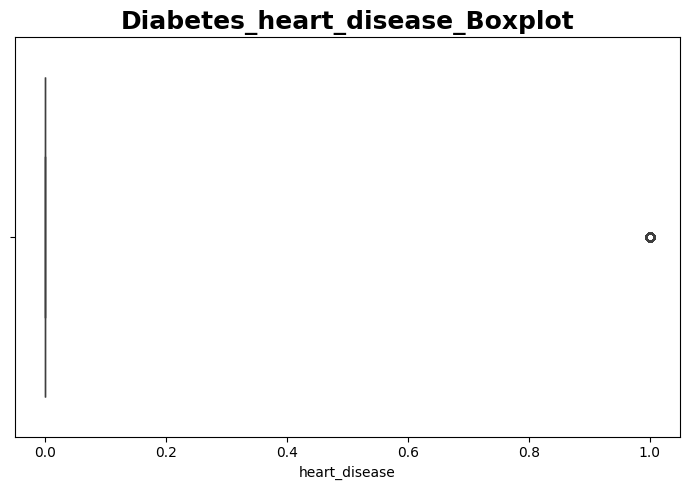

In [ ]:
plot_boxplots(cvd_df, "CVD")

plot_boxplots(diab_df, "Diabetes")

In [ ]:
# ============================================================
# ZIP ALL GENERATED FIGURES
# ============================================================

import shutil
from google.colab import files

# Name of zip file
zip_filename = "Heart_Disease_EDA_Figures"

# Create zip
shutil.make_archive(
    zip_filename,
    'zip',
    'Results/Figures'
)

print(f"{zip_filename}.zip created successfully.")

# Download
files.download(f"{zip_filename}.zip")

Heart_Disease_EDA_Figures.zip created successfully.


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
def backup_results(section_name):
    """
    Creates a ZIP backup of the Results folder after each major section.
    Example:
        backup_results("EDA")
        backup_results("Preprocessing")
        backup_results("Hybrid_Models")
    """
    import shutil
    from google.colab import files

    zip_name = f"Backup_{section_name}"
    shutil.make_archive(zip_name, 'zip', 'Results')
    files.download(f"{zip_name}.zip")

In [ ]:
# ============================================================
# Section 3 : Dataset Specific Preprocessing
# ============================================================

from sklearn.preprocessing import LabelEncoder
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split

In [ ]:
general_health_map = {
    "Poor":0,
    "Fair":1,
    "Good":2,
    "Very Good":3,
    "Excellent":4
}

In [ ]:
checkup_map = {
    "Never":0,
    "5 or more years ago":1,
    "Within the past 5 years":2,
    "Within the past 2 years":3,
    "Within the past year":4
}

In [ ]:
age_category_map = {

"18-24":0,
"25-29":1,
"30-34":2,
"35-39":3,
"40-44":4,
"45-49":5,
"50-54":6,
"55-59":7,
"60-64":8,
"65-69":9,
"70-74":10,
"75-79":11,
"80+":12

}

In [ ]:
binary_map = {

"Yes":1,
"No":0,

"Male":1,
"Female":0

}

In [ ]:
print(cvd_df["Diabetes"].unique())

['No' 'Yes' 'No, pre-diabetes or borderline diabetes'
 'Yes, but female told only during pregnancy']


In [ ]:
cvd_df["General_Health"] = cvd_df["General_Health"].map(general_health_map)

cvd_df["Checkup"] = cvd_df["Checkup"].map(checkup_map)

cvd_df["Age_Category"] = cvd_df["Age_Category"].map(age_category_map)

In [ ]:
binary_columns = [

"Exercise",
"Skin_Cancer",
"Other_Cancer",
"Depression",
"Arthritis",
"Smoking_History",
"Sex"

]

for col in binary_columns:

    cvd_df[col] = cvd_df[col].map(binary_map)

In [ ]:
gender_map = {

"Female":0,
"Male":1,
"Other":2

}

cvd_dummy = None

diab_df["gender"] = diab_df["gender"].map(gender_map)

In [ ]:
print(diab_df["smoking_history"].unique())

['never' 'No Info' 'current' 'former' 'ever' 'not current']


In [ ]:
# ============================================================
# Diabetes Mapping (Clinical Ordering)
# ============================================================

diabetes_map = {

    "No": 0,

    "No, pre-diabetes or borderline diabetes": 1,

    "Yes, but female told only during pregnancy": 2,

    "Yes": 3

}

cvd_df["Diabetes"] = cvd_df["Diabetes"].map(diabetes_map)

In [ ]:
# ============================================================
# One-Hot Encoding for Smoking History
# ============================================================

diab_df = pd.get_dummies(
    diab_df,
    columns=["smoking_history"],
    prefix="Smoking",
    drop_first=False
)

In [ ]:
# ============================================================
# Gender Encoding
# ============================================================

gender_map = {

    "Female":0,
    "Male":1,
    "Other":2

}

diab_df["gender"] = diab_df["gender"].map(gender_map)

In [ ]:
# ============================================================
# Target Encoding
# ============================================================

cvd_df["Heart_Disease"] = cvd_df["Heart_Disease"].map({

    "No":0,

    "Yes":1

})

In [ ]:
# ============================================================
# Verify Encodings
# ============================================================

print("="*70)
print("CVD Dataset")
print("="*70)

display(cvd_df.head())

print("\n")

print("="*70)
print("Diabetes Dataset")
print("="*70)

display(diab_df.head())

CVD Dataset


,General_Health,Checkup,Exercise,Skin_Cancer,Other_Cancer,Depression,Diabetes,Arthritis,Sex,Age_Category,Height_(cm),Weight_(kg),BMI,Smoking_History,Alcohol_Consumption,Fruit_Consumption,Green_Vegetables_Consumption,FriedPotato_Consumption,Heart_Disease
0,0,3,0,0,0,0,0,1,0,10,150,32.66,14.54,1,0,30,16,12,0
1,3,4,0,0,0,0,3,0,0,10,165,77.11,28.29,0,0,30,0,4,1
2,3,4,1,0,0,0,3,0,0,8,163,88.45,33.47,0,4,12,3,16,0
3,0,4,1,0,0,0,3,0,1,11,180,93.44,28.73,0,0,30,30,8,1
4,2,4,0,0,0,0,0,0,1,12,191,88.45,24.37,1,0,8,4,0,0




Diabetes Dataset


,gender,age,hypertension,bmi,HbA1c_level,blood_glucose_level,diabetes,heart_disease,Smoking_No Info,Smoking_current,Smoking_ever,Smoking_former,Smoking_never,Smoking_not current
0,NaN,80.0,0,25.19,6.6,140,0,1,False,False,False,False,True,False
1,NaN,54.0,0,27.32,6.6,80,0,0,True,False,False,False,False,False
2,NaN,28.0,0,27.32,5.7,158,0,0,False,False,False,False,True,False
3,NaN,36.0,0,23.45,5.0,155,0,0,False,True,False,False,False,False
4,NaN,76.0,1,20.14,4.8,155,0,1,False,True,False,False,False,False


In [ ]:
# ============================================================
# Feature and Target Separation
# ============================================================

cvd_target = "Heart_Disease"

diab_target = "heart_disease"

cvd_features = [col for col in cvd_df.columns if col != cvd_target]

diab_features = [col for col in diab_df.columns if col != diab_target]

print("CVD Features :", len(cvd_features))
print("Diabetes Features :", len(diab_features))

CVD Features : 18
Diabetes Features : 13


In [ ]:
cvd_numeric = [
    "Height_(cm)",
    "Weight_(kg)",
    "BMI",
    "Alcohol_Consumption",
    "Fruit_Consumption",
    "Green_Vegetables_Consumption",
    "FriedPotato_Consumption"
]

In [ ]:
diab_numeric = [
    "age",
    "bmi",
    "HbA1c_level",
    "blood_glucose_level"
]

In [ ]:
# ============================================================
# Standard Scaling
# ============================================================

scaler_cvd = StandardScaler()
scaler_diab = StandardScaler()

cvd_df[cvd_numeric] = scaler_cvd.fit_transform(cvd_df[cvd_numeric])

diab_df[diab_numeric] = scaler_diab.fit_transform(diab_df[diab_numeric])

print("Scaling completed successfully.")

Scaling completed successfully.


In [ ]:
# ============================================================
# Save Preprocessed Datasets
# ============================================================

cvd_df.to_csv(
    "Results/CVD_Preprocessed.csv",
    index=False
)

diab_df.to_csv(
    "Results/Diabetes_Preprocessed.csv",
    index=False
)

print("Preprocessed datasets saved successfully.")

Preprocessed datasets saved successfully.


In [ ]:
# ============================================================
# Train-Test Split : CVD Dataset
# ============================================================

X_cvd = cvd_df.drop(columns=["Heart_Disease"])
y_cvd = cvd_df["Heart_Disease"]

X_train_cvd, X_test_cvd, y_train_cvd, y_test_cvd = train_test_split(
    X_cvd,
    y_cvd,
    test_size=0.20,
    random_state=42,
    stratify=y_cvd
)

print("="*60)
print("CVD Dataset")
print("="*60)
print("Training :", X_train_cvd.shape)
print("Testing  :", X_test_cvd.shape)

CVD Dataset
Training : (247019, 18)
Testing  : (61755, 18)


In [ ]:
# ============================================================
# Train-Test Split : Diabetes Dataset
# ============================================================

X_diab = diab_df.drop(columns=["heart_disease"])
y_diab = diab_df["heart_disease"]

X_train_diab, X_test_diab, y_train_diab, y_test_diab = train_test_split(
    X_diab,
    y_diab,
    test_size=0.20,
    random_state=42,
    stratify=y_diab
)

print("="*60)
print("Diabetes Dataset")
print("="*60)
print("Training :", X_train_diab.shape)
print("Testing  :", X_test_diab.shape)

Diabetes Dataset
Training : (76916, 13)
Testing  : (19230, 13)


In [ ]:
# ============================================================
# Section 6
# Clinical Interaction Representation Learning (Enhanced CIRL)
# ============================================================

from itertools import combinations
from sklearn.feature_selection import mutual_info_classif

class CIRL:

    def __init__(self,
                 interaction_columns,
                 top_k=15):

        self.interaction_columns = interaction_columns
        self.top_k = top_k
        self.selected_features = []

    def fit_transform(self,
                      X,
                      y):

        X_new = X.copy()

        interaction_names = []

        # Generate pairwise interactions
        for col1, col2 in combinations(self.interaction_columns, 2):

            name = f"{col1}_X_{col2}"

            X_new[name] = X[col1] * X[col2]

            interaction_names.append(name)

        # Rank only interaction features
        mi = mutual_info_classif(
            X_new[interaction_names],
            y,
            random_state=42
        )

        ranking = pd.DataFrame({

            "Feature": interaction_names,
            "MI": mi

        })

        ranking = ranking.sort_values(
            by="MI",
            ascending=False
        )

        self.selected_features = ranking.head(self.top_k)["Feature"].tolist()

        final_columns = list(X.columns) + self.selected_features

        return X_new[final_columns]

    def transform(self,
                  X):

        X_new = X.copy()

        for col1, col2 in combinations(self.interaction_columns,2):

            name = f"{col1}_X_{col2}"

            X_new[name] = X[col1] * X[col2]

        final_columns = list(X.columns) + self.selected_features

        return X_new[final_columns]

In [ ]:
# ============================================================
# Enhanced CIRL : CVD Dataset
# ============================================================

cvd_interaction_cols = [

    "Age_Category",
    "BMI",
    "Diabetes",
    "Smoking_History",
    "Exercise",
    "General_Health"

]

cirl_cvd = CIRL(
    interaction_columns=cvd_interaction_cols,
    top_k=12
)

X_train_cvd_cirl = cirl_cvd.fit_transform(
    X_train_cvd,
    y_train_cvd
)

X_test_cvd_cirl = cirl_cvd.transform(
    X_test_cvd
)

print("="*60)
print("CVD Dataset")
print("="*60)
print("Original Features :", X_train_cvd.shape[1])
print("Selected Interaction Features :", len(cirl_cvd.selected_features))
print("Final Features :", X_train_cvd_cirl.shape[1])

CVD Dataset
Original Features : 18
Selected Interaction Features : 12
Final Features : 30


In [ ]:
# ============================================================
# Enhanced CIRL : Diabetes Dataset
# ============================================================

diab_interaction_cols = [

    "age",
    "bmi",
    "HbA1c_level",
    "blood_glucose_level",
    "diabetes",
    "hypertension"

]

cirl_diab = CIRL(
    interaction_columns=diab_interaction_cols,
    top_k=10
)

X_train_diab_cirl = cirl_diab.fit_transform(
    X_train_diab,
    y_train_diab
)

X_test_diab_cirl = cirl_diab.transform(
    X_test_diab
)

print("="*60)
print("Diabetes Dataset")
print("="*60)
print("Original Features :", X_train_diab.shape[1])
print("Selected Interaction Features :", len(cirl_diab.selected_features))
print("Final Features :", X_train_diab_cirl.shape[1])

Diabetes Dataset
Original Features : 13
Selected Interaction Features : 10
Final Features : 23


In [ ]:
# ============================================================
# Save Selected Clinical Interactions
# ============================================================

pd.DataFrame({
    "Selected_Interactions": cirl_cvd.selected_features
}).to_csv(
    "Results/Tables/CVD_Selected_Interactions.csv",
    index=False
)

pd.DataFrame({
    "Selected_Interactions": cirl_diab.selected_features
}).to_csv(
    "Results/Tables/Diabetes_Selected_Interactions.csv",
    index=False
)

print("Selected interaction features saved successfully.")

Selected interaction features saved successfully.


In [ ]:
X_train_diab_cirl, diab_created = generate_interaction_features(

    X_train_diab,

    diab_interaction_cols

)

X_test_diab_cirl,_ = generate_interaction_features(

    X_test_diab,

    diab_interaction_cols

)

print("Original :",X_train_diab.shape[1])

print("Interactions :",len(diab_created))

print("Total :",X_train_diab_cirl.shape[1])

Original : 13
Interactions : 15
Total : 28


In [ ]:
# ============================================================
# Convert to NumPy
# ============================================================

X_train_cvd_np = X_train_cvd_cirl.values.astype(np.float32)
X_test_cvd_np = X_test_cvd_cirl.values.astype(np.float32)

y_train_cvd_np = y_train_cvd.values.astype(np.float32)
y_test_cvd_np = y_test_cvd.values.astype(np.float32)


X_train_diab_np = X_train_diab_cirl.values.astype(np.float32)
X_test_diab_np = X_test_diab_cirl.values.astype(np.float32)

y_train_diab_np = y_train_diab.values.astype(np.float32)
y_test_diab_np = y_test_diab.values.astype(np.float32)

print("NumPy Conversion Completed")

NumPy Conversion Completed


In [ ]:
# ============================================================
# PyTorch Dataset
# ============================================================

class HeartDataset(Dataset):

    def __init__(self,
                 X,
                 y):

        self.X = torch.tensor(
            X,
            dtype=torch.float32
        )

        self.y = torch.tensor(
            y,
            dtype=torch.float32
        )

    def __len__(self):

        return len(self.X)

    def __getitem__(self,
                    idx):

        return self.X[idx], self.y[idx]

In [ ]:
# ============================================================
# Dataset Objects
# ============================================================

train_dataset_cvd = HeartDataset(
    X_train_cvd_np,
    y_train_cvd_np
)

test_dataset_cvd = HeartDataset(
    X_test_cvd_np,
    y_test_cvd_np
)

train_dataset_diab = HeartDataset(
    X_train_diab_np,
    y_train_diab_np
)

test_dataset_diab = HeartDataset(
    X_test_diab_np,
    y_test_diab_np
)

print("Dataset Objects Created")

Dataset Objects Created


In [ ]:
# ============================================================
# DataLoader
# ============================================================

BATCH_SIZE = 256

train_loader_cvd = DataLoader(
    train_dataset_cvd,
    batch_size=BATCH_SIZE,
    shuffle=True
)

test_loader_cvd = DataLoader(
    test_dataset_cvd,
    batch_size=BATCH_SIZE,
    shuffle=False
)

train_loader_diab = DataLoader(
    train_dataset_diab,
    batch_size=BATCH_SIZE,
    shuffle=True
)

test_loader_diab = DataLoader(
    test_dataset_diab,
    batch_size=BATCH_SIZE,
    shuffle=False
)

print("DataLoaders Ready")

DataLoaders Ready


In [ ]:
# ============================================================
# Focal Loss
# ============================================================

import torch
import torch.nn as nn
import torch.nn.functional as F

class FocalLoss(nn.Module):

    def __init__(self,
                 alpha=0.75,
                 gamma=2.0):

        super().__init__()

        self.alpha = alpha
        self.gamma = gamma

    def forward(self,
                inputs,
                targets):

        targets = targets.view(-1,1)

        bce = F.binary_cross_entropy_with_logits(
            inputs,
            targets,
            reduction='none'
        )

        pt = torch.exp(-bce)

        loss = self.alpha*((1-pt)**self.gamma)*bce

        return loss.mean()

In [ ]:
# ============================================================
# Clinical Embedding MLP
# ============================================================

class ClinicalMLP(nn.Module):

    def __init__(self,
                 input_dim,
                 embedding_dim=64):

        super().__init__()

        self.feature_extractor = nn.Sequential(

            nn.Linear(input_dim,256),

            nn.BatchNorm1d(256),

            nn.GELU(),

            nn.Dropout(0.30),

            nn.Linear(256,128),

            nn.BatchNorm1d(128),

            nn.GELU(),

            nn.Dropout(0.20),

            nn.Linear(128,embedding_dim),

            nn.GELU()

        )

        self.classifier = nn.Linear(
            embedding_dim,
            1
        )

    def forward(self,x):

        embedding = self.feature_extractor(x)

        prediction = self.classifier(embedding)

        return embedding,prediction

In [ ]:
# ============================================================
# Build Model
# ============================================================

INPUT_DIM = X_train_cvd_np.shape[1]

mlp_model = ClinicalMLP(
    input_dim=INPUT_DIM,
    embedding_dim=64
)

mlp_model = mlp_model.to(device)

print(mlp_model)

ClinicalMLP(
  (feature_extractor): Sequential(
    (0): Linear(in_features=30, out_features=256, bias=True)
    (1): BatchNorm1d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): GELU(approximate='none')
    (3): Dropout(p=0.3, inplace=False)
    (4): Linear(in_features=256, out_features=128, bias=True)
    (5): BatchNorm1d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (6): GELU(approximate='none')
    (7): Dropout(p=0.2, inplace=False)
    (8): Linear(in_features=128, out_features=64, bias=True)
    (9): GELU(approximate='none')
  )
  (classifier): Linear(in_features=64, out_features=1, bias=True)
)


In [ ]:
# ============================================================
# Optimizer
# ============================================================

criterion = FocalLoss()

optimizer = torch.optim.AdamW(

    mlp_model.parameters(),

    lr=1e-3,

    weight_decay=1e-4

)

In [ ]:
# ============================================================
# Training Function
# ============================================================

def train_epoch(model,
                loader,
                optimizer,
                criterion):

    model.train()

    total_loss = 0

    for x,y in loader:

        x = x.to(device)

        y = y.to(device)

        optimizer.zero_grad()

        _,pred = model(x)

        loss = criterion(pred,y)

        loss.backward()

        optimizer.step()

        total_loss += loss.item()

    return total_loss/len(loader)

In [ ]:
# ============================================================
# Validation Function
# ============================================================

def validate_epoch(model,
                   loader,
                   criterion):

    model.eval()

    total_loss = 0

    predictions = []

    probabilities = []

    labels = []

    with torch.no_grad():

        for x,y in loader:

            x = x.to(device)

            y = y.to(device)

            _,pred = model(x)

            loss = criterion(pred,y)

            total_loss += loss.item()

            prob = torch.sigmoid(pred)

            probabilities.extend(
                prob.cpu().numpy().flatten()
            )

            predictions.extend(
                (prob>0.5).cpu().numpy().flatten()
            )

            labels.extend(
                y.cpu().numpy()
            )

    return (

        total_loss/len(loader),

        predictions,

        probabilities,

        labels

    )

In [ ]:
# ============================================================
# Train Clinical MLP
# ============================================================

EPOCHS = 30

train_loss_history = []

val_loss_history = []

for epoch in range(EPOCHS):

    train_loss = train_epoch(

        mlp_model,

        train_loader_cvd,

        optimizer,

        criterion

    )

    val_loss,_,_,_ = validate_epoch(

        mlp_model,

        test_loader_cvd,

        criterion

    )

    train_loss_history.append(train_loss)

    val_loss_history.append(val_loss)

    print(

        f"Epoch {epoch+1:02d}/{EPOCHS}"

        f" | Train Loss : {train_loss:.4f}"

        f" | Val Loss : {val_loss:.4f}"

    )

Epoch 01/30 | Train Loss : 0.0466 | Val Loss : 0.0450
Epoch 02/30 | Train Loss : 0.0453 | Val Loss : 0.0445
Epoch 03/30 | Train Loss : 0.0451 | Val Loss : 0.0446
Epoch 04/30 | Train Loss : 0.0450 | Val Loss : 0.0444
Epoch 05/30 | Train Loss : 0.0450 | Val Loss : 0.0445
Epoch 06/30 | Train Loss : 0.0449 | Val Loss : 0.0445
Epoch 07/30 | Train Loss : 0.0449 | Val Loss : 0.0445
Epoch 08/30 | Train Loss : 0.0449 | Val Loss : 0.0444
Epoch 09/30 | Train Loss : 0.0448 | Val Loss : 0.0445
Epoch 10/30 | Train Loss : 0.0448 | Val Loss : 0.0444
Epoch 11/30 | Train Loss : 0.0447 | Val Loss : 0.0445
Epoch 12/30 | Train Loss : 0.0447 | Val Loss : 0.0444
Epoch 13/30 | Train Loss : 0.0447 | Val Loss : 0.0444
Epoch 14/30 | Train Loss : 0.0447 | Val Loss : 0.0444
Epoch 15/30 | Train Loss : 0.0447 | Val Loss : 0.0444
Epoch 16/30 | Train Loss : 0.0447 | Val Loss : 0.0444
Epoch 17/30 | Train Loss : 0.0446 | Val Loss : 0.0445
Epoch 18/30 | Train Loss : 0.0446 | Val Loss : 0.0443
Epoch 19/30 | Train Loss : 0

In [ ]:
# ============================================================
# Extract Clinical Embeddings
# ============================================================

def extract_embeddings(model, loader):

    model.eval()

    embeddings = []

    labels = []

    with torch.no_grad():

        for x, y in loader:

            x = x.to(device)

            emb, _ = model(x)

            embeddings.append(emb.cpu().numpy())

            labels.append(y.numpy())

    embeddings = np.vstack(embeddings)
    labels = np.concatenate(labels)

    return embeddings, labels

In [ ]:
# ============================================================
# Generate Train/Test Embeddings
# ============================================================

train_embedding_cvd, train_label_cvd = extract_embeddings(
    mlp_model,
    train_loader_cvd
)

test_embedding_cvd, test_label_cvd = extract_embeddings(
    mlp_model,
    test_loader_cvd
)

print("Training Embedding Shape :", train_embedding_cvd.shape)
print("Testing Embedding Shape :", test_embedding_cvd.shape)

Training Embedding Shape : (247019, 64)
Testing Embedding Shape : (61755, 64)


In [ ]:
# ============================================================
# Save Clinical Embeddings
# ============================================================

np.save(
    "Results/Models/CVD_MLP_Train_Embedding.npy",
    train_embedding_cvd
)

np.save(
    "Results/Models/CVD_MLP_Test_Embedding.npy",
    test_embedding_cvd
)

print("Embeddings Saved Successfully.")

Embeddings Saved Successfully.


In [ ]:
# ============================================================
# Original Features + Clinical Embeddings
# ============================================================

X_train_hybrid = np.concatenate(
    [
        X_train_cvd_np,
        train_embedding_cvd
    ],
    axis=1
)

X_test_hybrid = np.concatenate(
    [
        X_test_cvd_np,
        test_embedding_cvd
    ],
    axis=1
)

print("Hybrid Train Shape :", X_train_hybrid.shape)
print("Hybrid Test Shape :", X_test_hybrid.shape)

Hybrid Train Shape : (247019, 94)
Hybrid Test Shape : (61755, 94)


In [ ]:
# ============================================================
# Save Hybrid Feature Matrix
# ============================================================

np.save(
    "Results/Models/CVD_Hybrid_Train.npy",
    X_train_hybrid
)

np.save(
    "Results/Models/CVD_Hybrid_Test.npy",
    X_test_hybrid
)

print("Hybrid Features Saved.")

Hybrid Features Saved.


In [ ]:
# ============================================================
# Hybrid Model 1 : MLP + XGBoost
# ============================================================

from xgboost import XGBClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    matthews_corrcoef,
    confusion_matrix
)

In [ ]:
# ============================================================
# Feature Sets
# ============================================================

# Original Features
X_train_original = X_train_cvd_np
X_test_original = X_test_cvd_np

# MLP Embeddings
X_train_embedding = train_embedding_cvd
X_test_embedding = test_embedding_cvd

# Hybrid Features
X_train_hybrid = X_train_hybrid
X_test_hybrid = X_test_hybrid

print("Original :", X_train_original.shape)
print("Embedding :", X_train_embedding.shape)
print("Hybrid :", X_train_hybrid.shape)

Original : (247019, 30)
Embedding : (247019, 64)
Hybrid : (247019, 94)


In [ ]:
# ============================================================
# Evaluation Function
# ============================================================

def evaluate_model(model,
                   X_train,
                   y_train,
                   X_test,
                   y_test):

    model.fit(X_train,y_train)

    pred = model.predict(X_test)

    prob = model.predict_proba(X_test)[:,1]

    metrics = {

        "Accuracy":accuracy_score(y_test,pred),

        "Precision":precision_score(y_test,pred),

        "Recall":recall_score(y_test,pred),

        "F1":f1_score(y_test,pred),

        "AUROC":roc_auc_score(y_test,prob),

        "MCC":matthews_corrcoef(y_test,pred)

    }

    return metrics,pred,prob

In [ ]:
# ============================================================
# XGBoost Parameters
# ============================================================

xgb_model = XGBClassifier(

    n_estimators=300,

    max_depth=6,

    learning_rate=0.05,

    subsample=0.8,

    colsample_bytree=0.8,

    objective="binary:logistic",

    eval_metric="logloss",

    random_state=42,

    tree_method="hist",

    n_jobs=-1,

    scale_pos_weight=11.5

)

In [ ]:
# ============================================================
# XGBoost : Original Features
# ============================================================

metrics_original, pred_original, prob_original = evaluate_model(

    xgb_model,

    X_train_original,
    y_train_cvd,

    X_test_original,
    y_test_cvd

)

print(metrics_original)

{'Accuracy': 0.7346773540604, 'Precision': 0.20606905093667752, 'Recall': 0.7995594713656388, 'F1': 0.32768454310450945, 'AUROC': np.float64(0.8391242849887827), 'MCC': np.float64(0.31053034174365973)}


In [ ]:
# ============================================================
# XGBoost : Embeddings
# ============================================================

xgb_model = XGBClassifier(

    n_estimators=300,

    max_depth=6,

    learning_rate=0.05,

    subsample=0.8,

    colsample_bytree=0.8,

    objective="binary:logistic",

    eval_metric="logloss",

    random_state=42,

    tree_method="hist",

    n_jobs=-1,

    scale_pos_weight=11.5

)

metrics_embedding, pred_embedding, prob_embedding = evaluate_model(

    xgb_model,

    X_train_embedding,
    y_train_cvd,

    X_test_embedding,
    y_test_cvd

)

print(metrics_embedding)

{'Accuracy': 0.6598170188648692, 'Precision': 0.09392433309666295, 'Recall': 0.3708450140168202, 'F1': 0.1498866947232114, 'AUROC': np.float64(0.5376619170502357), 'MCC': np.float64(0.0327990626336253)}


In [ ]:
# ============================================================
# Hybrid Model : MLP + XGBoost
# ============================================================

xgb_model = XGBClassifier(

    n_estimators=300,

    max_depth=6,

    learning_rate=0.05,

    subsample=0.8,

    colsample_bytree=0.8,

    objective="binary:logistic",

    eval_metric="logloss",

    random_state=42,

    tree_method="hist",

    n_jobs=-1,

    scale_pos_weight=11.5

)

metrics_hybrid, pred_hybrid, prob_hybrid = evaluate_model(

    xgb_model,

    X_train_hybrid,
    y_train_cvd,

    X_test_hybrid,
    y_test_cvd

)

print(metrics_hybrid)

{'Accuracy': 0.7513237794510566, 'Precision': 0.21428177557209815, 'Recall': 0.7781337605126152, 'F1': 0.3360283626615937, 'AUROC': np.float64(0.8376699138206524), 'MCC': np.float64(0.31552925942918614)}


In [ ]:
# ============================================================
# Threshold Optimization
# ============================================================

from sklearn.metrics import f1_score, matthews_corrcoef

thresholds = np.arange(0.10, 0.91, 0.01)

best_threshold = 0.50
best_f1 = 0
best_mcc = 0

for t in thresholds:

    pred = (prob_hybrid >= t).astype(int)

    f1 = f1_score(y_test_cvd, pred)
    mcc = matthews_corrcoef(y_test_cvd, pred)

    if f1 > best_f1:
        best_f1 = f1
        best_mcc = mcc
        best_threshold = t

print("="*60)
print("Best Threshold :", best_threshold)
print("Best F1 :", best_f1)
print("Best MCC :", best_mcc)

Best Threshold : 0.6799999999999997
Best F1 : 0.37565217391304345
Best MCC : 0.3235000564609045


In [ ]:
# ============================================================
# FT Transformer
# ============================================================

import torch
import torch.nn as nn
import torch.nn.functional as F

In [ ]:
# ============================================================
# Feature Tokenizer
# ============================================================

class FeatureTokenizer(nn.Module):

    def __init__(self,
                 input_dim,
                 embed_dim):

        super().__init__()

        self.weight = nn.Parameter(
            torch.randn(input_dim,embed_dim)
        )

        self.bias = nn.Parameter(
            torch.randn(input_dim,embed_dim)
        )

    def forward(self,x):

        x = x.unsqueeze(-1)

        return x*self.weight+self.bias

In [ ]:
# ============================================================
# Transformer Block
# ============================================================

class TransformerBlock(nn.Module):

    def __init__(self,
                 embed_dim,
                 num_heads,
                 dropout):

        super().__init__()

        self.attention = nn.MultiheadAttention(
            embed_dim,
            num_heads,
            dropout=dropout,
            batch_first=True
        )

        self.norm1 = nn.LayerNorm(embed_dim)

        self.ffn = nn.Sequential(

            nn.Linear(embed_dim,embed_dim*4),

            nn.GELU(),

            nn.Dropout(dropout),

            nn.Linear(embed_dim*4,embed_dim)

        )

        self.norm2 = nn.LayerNorm(embed_dim)

    def forward(self,x):

        attn,_ = self.attention(x,x,x)

        x = self.norm1(x+attn)

        ffn = self.ffn(x)

        x = self.norm2(x+ffn)

        return x

In [ ]:
# ============================================================
# Clinical FT Transformer
# ============================================================

class ClinicalFTTransformer(nn.Module):

    def __init__(self,
                 input_dim,
                 embed_dim=64,
                 heads=4,
                 layers=3):

        super().__init__()

        self.tokenizer = FeatureTokenizer(
            input_dim,
            embed_dim
        )

        self.blocks = nn.ModuleList([

            TransformerBlock(
                embed_dim,
                heads,
                0.20
            )

            for _ in range(layers)

        ])

        self.pool = nn.AdaptiveAvgPool1d(1)

        self.embedding = nn.Linear(
            embed_dim,
            64
        )

        self.classifier = nn.Linear(
            64,
            1
        )

    def forward(self,x):

        x = self.tokenizer(x)

        for block in self.blocks:

            x = block(x)

        x = x.transpose(1,2)

        x = self.pool(x).squeeze(-1)

        embedding = self.embedding(x)

        prediction = self.classifier(embedding)

        return embedding,prediction

In [ ]:
# ============================================================
# Build FT Transformer
# ============================================================

ft_model = ClinicalFTTransformer(

    input_dim=X_train_cvd_np.shape[1],

    embed_dim=64,

    heads=4,

    layers=3

)

ft_model = ft_model.to(device)

print(ft_model)

ClinicalFTTransformer(
  (tokenizer): FeatureTokenizer()
  (blocks): ModuleList(
    (0-2): 3 x TransformerBlock(
      (attention): MultiheadAttention(
        (out_proj): NonDynamicallyQuantizableLinear(in_features=64, out_features=64, bias=True)
      )
      (norm1): LayerNorm((64,), eps=1e-05, elementwise_affine=True)
      (ffn): Sequential(
        (0): Linear(in_features=64, out_features=256, bias=True)
        (1): GELU(approximate='none')
        (2): Dropout(p=0.2, inplace=False)
        (3): Linear(in_features=256, out_features=64, bias=True)
      )
      (norm2): LayerNorm((64,), eps=1e-05, elementwise_affine=True)
    )
  )
  (pool): AdaptiveAvgPool1d(output_size=1)
  (embedding): Linear(in_features=64, out_features=64, bias=True)
  (classifier): Linear(in_features=64, out_features=1, bias=True)
)


In [ ]:
# ============================================================
# Optimizer
# ============================================================

criterion = FocalLoss()

optimizer = torch.optim.AdamW(

    ft_model.parameters(),

    lr=0.0005,

    weight_decay=1e-4

)

In [ ]:
# ============================================================
# Train FT Transformer
# ============================================================

EPOCHS = 30

ft_train_loss = []

ft_val_loss = []

for epoch in range(EPOCHS):

    train_loss = train_epoch(

        ft_model,

        train_loader_cvd,

        optimizer,

        criterion

    )

    val_loss,_,_,_ = validate_epoch(

        ft_model,

        test_loader_cvd,

        criterion

    )

    ft_train_loss.append(train_loss)

    ft_val_loss.append(val_loss)

    print(

        f"Epoch {epoch+1:02d}/{EPOCHS}"

        f" | Train : {train_loss:.4f}"

        f" | Val : {val_loss:.4f}"

    )

Epoch 01/30 | Train : 0.0467 | Val : 0.0455
Epoch 02/30 | Train : 0.0455 | Val : 0.0447
Epoch 03/30 | Train : 0.0453 | Val : 0.0449
Epoch 04/30 | Train : 0.0451 | Val : 0.0461
Epoch 05/30 | Train : 0.0451 | Val : 0.0446
Epoch 06/30 | Train : 0.0450 | Val : 0.0449
Epoch 07/30 | Train : 0.0450 | Val : 0.0445
Epoch 08/30 | Train : 0.0450 | Val : 0.0445
Epoch 09/30 | Train : 0.0450 | Val : 0.0445
Epoch 10/30 | Train : 0.0449 | Val : 0.0444
Epoch 11/30 | Train : 0.0449 | Val : 0.0446
Epoch 12/30 | Train : 0.0449 | Val : 0.0445
Epoch 13/30 | Train : 0.0449 | Val : 0.0444
Epoch 14/30 | Train : 0.0449 | Val : 0.0447
Epoch 15/30 | Train : 0.0448 | Val : 0.0446
Epoch 16/30 | Train : 0.0448 | Val : 0.0444
Epoch 17/30 | Train : 0.0448 | Val : 0.0447
Epoch 18/30 | Train : 0.0448 | Val : 0.0444
Epoch 19/30 | Train : 0.0448 | Val : 0.0445
Epoch 20/30 | Train : 0.0448 | Val : 0.0443
Epoch 21/30 | Train : 0.0448 | Val : 0.0446
Epoch 22/30 | Train : 0.0448 | Val : 0.0447
Epoch 23/30 | Train : 0.0448 | V

In [95]:
# ============================================================
# Extract FT Embeddings
# ============================================================

train_embedding_ft, train_label_ft = extract_embeddings(
    ft_model,
    train_loader_cvd
)

test_embedding_ft, test_label_ft = extract_embeddings(
    ft_model,
    test_loader_cvd
)

print("Train Embedding :", train_embedding_ft.shape)
print("Test Embedding :", test_embedding_ft.shape)

Train Embedding : (247019, 64)
Test Embedding : (61755, 64)


In [96]:
# ============================================================
# Original + FT Embeddings
# ============================================================

X_train_ft = np.concatenate(
    [
        X_train_cvd_np,
        train_embedding_ft
    ],
    axis=1
)

X_test_ft = np.concatenate(
    [
        X_test_cvd_np,
        test_embedding_ft
    ],
    axis=1
)

print(X_train_ft.shape)
print(X_test_ft.shape)

(247019, 94)
(61755, 94)


In [97]:
# ============================================================
# FT + CatBoost
# ============================================================

from catboost import CatBoostClassifier

cat_model = CatBoostClassifier(

    iterations=300,

    learning_rate=0.05,

    depth=6,

    loss_function="Logloss",

    eval_metric="AUC",

    random_seed=42,

    verbose=False,

    auto_class_weights="Balanced"

)

In [98]:
# ============================================================
# Evaluate FT + CatBoost
# ============================================================

metrics_cat, pred_cat, prob_cat = evaluate_model(

    cat_model,

    X_train_ft,
    y_train_cvd,

    X_test_ft,
    y_test_cvd

)

print(metrics_cat)

{'Accuracy': 0.7264351064691118, 'Precision': 0.2033010870649247, 'Recall': 0.816379655586704, 'F1': 0.3255349728521239, 'AUROC': np.float64(0.8400586649963995), 'MCC': np.float64(0.31142186441454583)}


In [99]:
# ============================================================
# FT + LightGBM
# ============================================================

from lightgbm import LGBMClassifier

lgb_model = LGBMClassifier(

    n_estimators=300,

    learning_rate=0.05,

    max_depth=6,

    random_state=42,

    class_weight="balanced"

)

In [100]:
# ============================================================
# Evaluate FT + LightGBM
# ============================================================

metrics_lgb, pred_lgb, prob_lgb = evaluate_model(

    lgb_model,

    X_train_ft,
    y_train_cvd,

    X_test_ft,
    y_test_cvd

)

print(metrics_lgb)

[LightGBM] [Info] Number of positive: 19977, number of negative: 227042
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.299743 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 18022
[LightGBM] [Info] Number of data points in the train set: 247019, number of used features: 94
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.500000 -> initscore=-0.000000
[LightGBM] [Info] Start training from score -0.000000
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
{'Accuracy': 0.7294793943810218, 'Precision': 0.20391343917484073, 'Recall': 0.8075690828994794, 'F1': 0.325609559179719, 'AUROC': np.float64(0.8365379340675946), 'MCC': np.float64(0.30979473827228715)}


In [101]:
# ============================================================
# Prepare Meta Features for ACFN
# ============================================================

# Training probabilities
prob_xgb_train = xgb_model.predict_proba(X_train_hybrid)[:, 1]
prob_cat_train = cat_model.predict_proba(X_train_ft)[:, 1]
prob_lgb_train = lgb_model.predict_proba(X_train_ft)[:, 1]

# Testing probabilities
prob_xgb_test = xgb_model.predict_proba(X_test_hybrid)[:, 1]
prob_cat_test = cat_model.predict_proba(X_test_ft)[:, 1]
prob_lgb_test = lgb_model.predict_proba(X_test_ft)[:, 1]

# Meta features
meta_train = np.column_stack([
    prob_xgb_train,
    prob_cat_train,
    prob_lgb_train
])

meta_test = np.column_stack([
    prob_xgb_test,
    prob_cat_test,
    prob_lgb_test
])

print(meta_train.shape)
print(meta_test.shape)

(247019, 3)
(61755, 3)


In [102]:
# ============================================================
# Meta Dataset
# ============================================================

train_meta_dataset = HeartDataset(
    meta_train.astype(np.float32),
    y_train_cvd.values.astype(np.float32)
)

test_meta_dataset = HeartDataset(
    meta_test.astype(np.float32),
    y_test_cvd.values.astype(np.float32)
)

train_meta_loader = DataLoader(
    train_meta_dataset,
    batch_size=512,
    shuffle=True
)

test_meta_loader = DataLoader(
    test_meta_dataset,
    batch_size=512,
    shuffle=False
)

In [103]:
# ============================================================
# Adaptive Confidence Fusion Network
# ============================================================

class ACFN(nn.Module):

    def __init__(self):

        super().__init__()

        self.network = nn.Sequential(

            nn.Linear(3, 32),
            nn.ReLU(),
            nn.Dropout(0.20),

            nn.Linear(32, 16),
            nn.ReLU(),

            nn.Linear(16, 1)

        )

    def forward(self, x):

        return self.network(x)

In [104]:
# ============================================================
# Build Model
# ============================================================

acfn = ACFN().to(device)

criterion = FocalLoss()

optimizer = torch.optim.Adam(
    acfn.parameters(),
    lr=0.001
)

In [106]:
# ============================================================
# Train ACFN
# ============================================================

EPOCHS = 30

# Local versions of training and validation functions adapted for ACFN
def train_epoch(model, loader, optimizer, criterion):
    model.train()
    total_loss = 0
    for x, y in loader:
        x = x.to(device)
        y = y.to(device)
        optimizer.zero_grad()
        # ACFN returns only prediction, not embedding and prediction
        pred = model(x)
        loss = criterion(pred, y)
        loss.backward()
        optimizer.step()
        total_loss += loss.item()
    return total_loss / len(loader)

def validate_epoch(model, loader, criterion):
    model.eval()
    total_loss = 0
    predictions = []
    probabilities = []
    labels = []
    with torch.no_grad():
        for x, y in loader:
            x = x.to(device)
            y = y.to(device)
            # ACFN returns only prediction, not embedding and prediction
            pred = model(x)
            loss = criterion(pred, y)
            total_loss += loss.item()
            prob = torch.sigmoid(pred)
            probabilities.extend(prob.cpu().numpy().flatten())
            predictions.extend((prob > 0.5).cpu().numpy().flatten())
            labels.extend(y.cpu().numpy())
    return (
        total_loss / len(loader),
        predictions,
        probabilities,
        labels
    )

for epoch in range(EPOCHS):

    train_loss = train_epoch(
        acfn,
        train_meta_loader,
        optimizer,
        criterion
    )

    val_loss, _, _, _ = validate_epoch(
        acfn,
        test_meta_loader,
        criterion
    )

    print(
        f"Epoch {epoch+1:02d}/{EPOCHS}"
        f" | Train: {train_loss:.4f}"
        f" | Val: {val_loss:.4f}"
    )


Epoch 01/30 | Train: 0.0477 | Val: 0.0456
Epoch 02/30 | Train: 0.0384 | Val: 0.0482
Epoch 03/30 | Train: 0.0361 | Val: 0.0516
Epoch 04/30 | Train: 0.0349 | Val: 0.0560
Epoch 05/30 | Train: 0.0342 | Val: 0.0564
Epoch 06/30 | Train: 0.0338 | Val: 0.0565
Epoch 07/30 | Train: 0.0335 | Val: 0.0579
Epoch 08/30 | Train: 0.0334 | Val: 0.0571
Epoch 09/30 | Train: 0.0333 | Val: 0.0587
Epoch 10/30 | Train: 0.0332 | Val: 0.0578
Epoch 11/30 | Train: 0.0331 | Val: 0.0575
Epoch 12/30 | Train: 0.0330 | Val: 0.0592
Epoch 13/30 | Train: 0.0330 | Val: 0.0577
Epoch 14/30 | Train: 0.0329 | Val: 0.0568
Epoch 15/30 | Train: 0.0329 | Val: 0.0589
Epoch 16/30 | Train: 0.0328 | Val: 0.0574
Epoch 17/30 | Train: 0.0329 | Val: 0.0596
Epoch 18/30 | Train: 0.0328 | Val: 0.0597
Epoch 19/30 | Train: 0.0327 | Val: 0.0579
Epoch 20/30 | Train: 0.0328 | Val: 0.0610
Epoch 21/30 | Train: 0.0327 | Val: 0.0607
Epoch 22/30 | Train: 0.0327 | Val: 0.0587
Epoch 23/30 | Train: 0.0327 | Val: 0.0618
Epoch 24/30 | Train: 0.0326 | Val:

In [107]:
# ============================================================
# Final Evaluation
# ============================================================

_, pred_meta, prob_meta, label_meta = validate_epoch(
    acfn,
    test_meta_loader,
    criterion
)

final_metrics = {

    "Accuracy": accuracy_score(label_meta, pred_meta),
    "Precision": precision_score(label_meta, pred_meta),
    "Recall": recall_score(label_meta, pred_meta),
    "F1": f1_score(label_meta, pred_meta),
    "AUROC": roc_auc_score(label_meta, prob_meta),
    "MCC": matthews_corrcoef(label_meta, pred_meta)

}

print(final_metrics)

{'Accuracy': 0.9100477694113837, 'Precision': 0.33470830878020036, 'Recall': 0.11373648378053665, 'F1': 0.16978030189807203, 'AUROC': np.float64(0.7921192804738247), 'MCC': np.float64(0.1565088881707867)}
